# Mercado de suplementos herbales en EE. UU.
### Análisis de etiquetas del Dietary Supplement Label Database (DSLD, NIH)

**Pregunta central:** ¿cómo es el mercado de suplementos herbales en EE. UU. (ingredientes, formatos, marcas y dosis) y qué espacios de oportunidad deja para un producto nuevo?

**Datos:** descarga completa del DSLD en CSV (10 de enero de 2026, 214,780 etiquetas). El segmento herbal son las etiquetas cuyo tipo de producto es *Botanical* o *Botanical with Nutrients*.

**Qué contiene este notebook**
1. Carga y limpieza
2. Diez análisis: ingredientes, formatos, rotación por ingrediente, marcas, combinaciones, dosis, ingredientes por formato, mezclas por forma, palabras en los títulos y atributos de etiqueta por año
3. Conclusiones y limitaciones
4. Dashboard resumen

**Cómo ejecutarlo en Google Colab:** sube a tu Drive, en `MyDrive/dsld/`, los dos archivos de la descarga completa del DSLD: `DSLD-full-database-CSV.zip` y `DSLD-full-database-JSON.zip`. Después ejecuta todas las celdas en orden (*Entorno de ejecución → Ejecutar todo*). El notebook genera solo, una vez, el archivo `dsld_json_extra.csv` con los campos que únicamente trae el JSON (tarda varios minutos). Sin el zip JSON corre completo salvo la sección de atributos por año (14).

## 1. Configuración

In [1]:
import glob
import itertools
import collections
import os
import re
import textwrap
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from mpl_toolkits.axes_grid1 import make_axes_locatable

# --- Rutas -------------------------------------------------------------------
# En Colab se monta Drive y se descomprime el zip. Para ejecutarlo en local,
# define las variables de entorno DSLD_DATA_DIR (carpeta con los CSV) y DSLD_OUT_DIR.
if "DSLD_DATA_DIR" in os.environ:
    DATA_DIR = os.environ["DSLD_DATA_DIR"]
    OUT_DIR = os.environ.get("DSLD_OUT_DIR", "salida")
    EXTRA_PATH = os.environ.get("DSLD_EXTRA_CSV", "dsld_json_extra.csv")
    JSON_ZIP = os.environ.get("DSLD_JSON_ZIP", "")
else:
    from google.colab import drive
    drive.mount("/content/drive")
    ZIP_PATH = "/content/drive/MyDrive/dsld/DSLD-full-database-CSV.zip"
    DATA_DIR = "/content/dsld_csv/DSLD-full-database-CSV"
    OUT_DIR = "/content/drive/MyDrive/dsld/salida"
    EXTRA_PATH = "/content/drive/MyDrive/dsld/dsld_json_extra.csv"
    JSON_ZIP = "/content/drive/MyDrive/dsld/DSLD-full-database-JSON.zip"
    if not os.path.isdir(DATA_DIR):
        with zipfile.ZipFile(ZIP_PATH) as z:
            z.extractall("/content/dsld_csv")

FIG_DIR = os.path.join(OUT_DIR, "figuras")
TAB_DIR = os.path.join(OUT_DIR, "tablas")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)
print("Datos:", DATA_DIR, "| Salida:", OUT_DIR)

### Campos extra del JSON (se genera una sola vez)

El CSV del DSLD no trae algunos datos (atributos como *Vegan* o *Sugar Free*, fechas de salida del mercado, relaciones entre etiquetas). Esos campos están en el JSON. La celda siguiente define la función `extraer()` (la misma de `dsld_extract_json.py`) y genera `dsld_json_extra.csv` en tu Drive si todavía no existe; después solo lo reutiliza.

In [2]:
import csv
import io
import json
import os
import sys
import zipfile
from collections import Counter

CAMPOS = [
    "dsld_id", "off_market", "entry_date", "off_market_date", "other_events",
    "claims", "target_groups", "relaciones", "n_relaciones",
    "net_qty", "net_unit", "serving_unit", "serving_min_qty", "serving_max_qty",
    "daily_servings_min", "daily_servings_max",
]

EVENTO_ENTRADA = "Date entered into DSLD"
EVENTO_SALIDA = "Off Market"


def unir(valores, sep=" | "):
    return sep.join(str(v).strip() for v in valores if v not in (None, ""))


def fila_de_etiqueta(j):
    eventos = {}
    otros = []
    for e in j.get("events") or []:
        tipo, fecha = e.get("type"), e.get("date")
        if tipo == EVENTO_ENTRADA:
            eventos["entry"] = fecha
        elif tipo == EVENTO_SALIDA:
            eventos["off"] = fecha
        else:
            otros.append(f"{tipo}:{fecha}")

    rel = j.get("labelRelationships") or []
    net = (j.get("netContents") or [{}])[0] or {}
    srv = (j.get("servingSizes") or [{}])[0] or {}

    return {
        "dsld_id": j.get("id"),
        "off_market": j.get("offMarket"),
        "entry_date": eventos.get("entry") or j.get("entryDate"),
        "off_market_date": eventos.get("off"),
        "other_events": ";".join(otros),
        "claims": unir(c.get("langualCodeDescription") for c in (j.get("claims") or [])),
        "target_groups": unir(j.get("targetGroups") or []),
        "relaciones": ";".join(f"{r.get('type')}:{r.get('labelId')}" for r in rel),
        "n_relaciones": len(rel),
        "net_qty": net.get("quantity"),
        "net_unit": net.get("unit"),
        "serving_unit": srv.get("unit"),
        "serving_min_qty": srv.get("minQuantity"),
        "serving_max_qty": srv.get("maxQuantity"),
        "daily_servings_min": srv.get("minDailyServings"),
        "daily_servings_max": srv.get("maxDailyServings"),
    }


def etiquetas_en(contenido):
    """Devuelve los objetos-etiqueta de un JSON (objeto o lista de objetos)."""
    datos = json.loads(contenido)
    if isinstance(datos, dict):
        return [datos]
    if isinstance(datos, list):
        return [d for d in datos if isinstance(d, dict)]
    return []


def es_json_valido(nombre):
    base = os.path.basename(nombre)
    return nombre.lower().endswith(".json") and not base.startswith(".") and "__MACOSX" not in nombre


def leer_zip(zf, origen):
    for nombre in zf.namelist():
        if es_json_valido(nombre):
            with zf.open(nombre) as fh:
                yield f"{origen}!{nombre}", fh.read()
        elif nombre.lower().endswith(".zip") and "__MACOSX" not in nombre:
            with zf.open(nombre) as fh:                 # zip dentro de zip
                interno = zipfile.ZipFile(io.BytesIO(fh.read()))
                yield from leer_zip(interno, f"{origen}!{nombre}")


def recorrer(ruta):
    if os.path.isfile(ruta) and ruta.lower().endswith(".zip"):
        with zipfile.ZipFile(ruta) as zf:
            yield from leer_zip(zf, os.path.basename(ruta))
        return
    for carpeta, _, nombres in os.walk(ruta):
        for n in sorted(nombres):
            ruta_n = os.path.join(carpeta, n)
            if n.lower().endswith(".zip") and not n.startswith("."):
                with zipfile.ZipFile(ruta_n) as zf:
                    yield from leer_zip(zf, n)
            elif es_json_valido(ruta_n):
                with open(ruta_n, "rb") as fh:
                    yield ruta_n, fh.read()


def extraer(entrada, salida):
    """Recorre ENTRADA (carpeta o .zip con los .json del DSLD) y escribe SALIDA (.csv)."""
    if not os.path.exists(entrada):
        raise FileNotFoundError(f"No existe: {entrada}")
    vistos, errores = set(), []
    eventos, n_archivos, n_etiquetas = Counter(), 0, 0
    with open(salida, "w", newline="", encoding="utf-8-sig") as out:
        w = csv.DictWriter(out, fieldnames=CAMPOS)
        w.writeheader()
        for origen, contenido in recorrer(entrada):
            n_archivos += 1
            try:
                for j in etiquetas_en(contenido):
                    fila = fila_de_etiqueta(j)
                    if fila["dsld_id"] in vistos:       # evita duplicados si hay partes repetidas
                        continue
                    vistos.add(fila["dsld_id"])
                    for e in j.get("events") or []:
                        eventos[e.get("type")] += 1
                    w.writerow(fila)
                    n_etiquetas += 1
            except Exception as exc:                    # un archivo raro no detiene el proceso
                errores.append((origen, repr(exc)))
            if n_archivos % 20000 == 0:
                print(f"  ... {n_archivos:,} archivos / {n_etiquetas:,} etiquetas", flush=True)

    print(f"\nArchivos leidos: {n_archivos:,} | etiquetas unicas: {n_etiquetas:,} | errores: {len(errores)}")
    print("Tipos de evento encontrados:", dict(eventos))
    for origen, exc in errores[:10]:
        print("  error:", origen, exc)
    print("Salida:", salida)
    return n_etiquetas


# --- Generar dsld_json_extra.csv si no existe ---------------------------------------
if os.path.exists(EXTRA_PATH):
    print("Ya existe", EXTRA_PATH, "- se reutiliza.")
elif JSON_ZIP and os.path.exists(JSON_ZIP):
    print("Extrayendo campos del JSON (tarda varios minutos; se hace una sola vez)...")
    extraer(JSON_ZIP, EXTRA_PATH)
else:
    print("No se encontró el zip JSON ni dsld_json_extra.csv: la sección de atributos por año se omitirá.")

### Estilo visual

Reglas que siguen todas las gráficas:
- **Una sola familia de color (azul).** Una serie = un azul (`#2a78d6`). Cuando hay dos categorías (*en mercado* / *descontinuado*), se usan dos pasos del mismo azul con alto contraste de luminosidad y etiquetas directas, para no depender solo del color.
- **Magnitud continua = rampa secuencial** de un solo tono, de claro a oscuro (mapa de calor).
- Marcas delgadas, rejilla tenue y sin bordes pesados; sin ejes duplicados; solo se etiquetan los valores que importan.
- Cada gráfica va acompañada de su **tabla**, para poder leer los números exactos.

In [3]:
# --- Paleta (azules) y tokens de estilo -----------------------------------------
SURFACE = "#ffffff"
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8985"   # texto principal, secundario, atenuado
GRID, AXIS = "#e6e5e1", "#c9c8c3"

BLUE = "#2a78d6"          # serie única
BLUE_DARK = "#184f95"     # categoría 1 en pares (p. ej. en mercado)
BLUE_LIGHT = "#6da7ec"    # categoría 2 en pares (p. ej. descontinuado)
RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("azules", RAMP)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.titleweight": "bold",
})

miles = FuncFormatter(lambda v, _: f"{v:,.0f}")


def estilo_ejes(ax, grid=None):
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(AXIS)
        ax.spines[lado].set_linewidth(0.8)
    ax.tick_params(length=0)
    ax.set_axisbelow(True)
    if grid:
        ax.grid(axis=grid, color=GRID, linewidth=0.8)
    else:
        ax.grid(False)


def titular(ax, titulo, subtitulo=None, size=12, pad=None, y_sub=1.015):
    ax.set_title(titulo, loc="left", fontsize=size, fontweight="bold", color=INK,
                 pad=pad if pad is not None else (24 if subtitulo else 8))
    if subtitulo:
        ax.text(0, y_sub, subtitulo, transform=ax.transAxes, fontsize=size - 3,
                color=INK_2, va="bottom")


def barras_h(ax, nombres, valores, etiquetas, color=BLUE, fs=8, alto=0.62):
    # Barras horizontales de una serie; el primer elemento queda arriba.
    y = np.arange(len(nombres))
    ax.barh(y, valores, height=alto, color=color, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(nombres, fontsize=fs + 1, color=INK)
    ax.invert_yaxis()
    vmax = max(valores)
    ax.set_xlim(0, vmax * 1.25)
    for yi, v, t in zip(y, valores, etiquetas):
        ax.text(v + vmax * 0.012, yi, t, va="center", fontsize=fs, color=INK_2)
    ax.xaxis.set_major_formatter(miles)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    estilo_ejes(ax, grid="x")


def apilado_h(ax, nombres, en_mercado, descontinuado, etiquetas, fs=8, alto=0.62):
    # Barras apiladas (en mercado + descontinuado) con etiqueta al final.
    y = np.arange(len(nombres))
    ax.barh(y, en_mercado, height=alto, color=BLUE_DARK, edgecolor=SURFACE, linewidth=1.5,
            label="En mercado", zorder=3)
    ax.barh(y, descontinuado, left=en_mercado, height=alto, color=BLUE_LIGHT,
            edgecolor=SURFACE, linewidth=1.5, label="Descontinuado", zorder=3)
    ax.set_yticks(y)
    ax.set_yticklabels(nombres, fontsize=fs + 1, color=INK)
    ax.invert_yaxis()
    totales = np.asarray(en_mercado) + np.asarray(descontinuado)
    vmax = totales.max()
    ax.set_xlim(0, vmax * 1.42)
    for yi, tot, t in zip(y, totales, etiquetas):
        ax.text(tot + vmax * 0.012, yi, t, va="center", fontsize=fs, color=INK_2)
    ax.xaxis.set_major_formatter(miles)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5))
    ax.legend(frameon=False, fontsize=fs, loc="lower right")
    estilo_ejes(ax, grid="x")


FORMA_ES = {
    "Capsule": "Cápsula", "Liquid": "Líquido", "Powder": "Polvo", "Tablet or Pill": "Tableta o pastilla",
    "Softgel Capsule": "Cápsula blanda", "Gummy or Jelly": "Gomita o jalea",
    "Other (e.g. tea bag)": "Otra (p. ej., té)", "Lozenge": "Pastilla para chupar",
    "Unknown": "Desconocida", "Bar": "Barra",
}


def envolver(texto, ancho=18):
    # Parte etiquetas largas en varias líneas para que no invadan el panel vecino.
    if " + " in texto:
        return texto.replace(" + ", "\n+ ")
    return "\n".join(textwrap.wrap(texto, ancho, break_long_words=False))


def guardar(fig, nombre):
    fig.savefig(os.path.join(FIG_DIR, nombre + ".png"), dpi=150, bbox_inches="tight")
    plt.show()

## 2. Carga de datos

El DSLD entrega cada tabla partida en 8 archivos. Se usan dos:
- **ProductOverview:** una fila por etiqueta (nombre, marca, tipo de producto, forma, fecha de entrada y estatus de mercado).
- **DietarySupplementFacts:** una fila por ingrediente declarado (nombre, categoría, cantidad y unidad).

In [4]:
def cargar(prefijo):
    archivos = sorted(glob.glob(f"{DATA_DIR}/{prefijo}_*.csv"))
    return pd.concat((pd.read_csv(f, dtype=str, keep_default_na=False) for f in archivos),
                     ignore_index=True)

productos = cargar("ProductOverview")
ingredientes = cargar("DietarySupplementFacts")
print(f"Etiquetas: {len(productos):,} | filas de ingredientes: {len(ingredientes):,}")

Etiquetas: 214,780 | filas de ingredientes: 2,020,130


## 3. Segmento herbal

Se conservan las etiquetas cuyo tipo de producto es **Botanical** o **Botanical with Nutrients**. Las etiquetas de otros tipos (por ejemplo *Other Combinations*) pueden contener algún botánico, pero casi siempre como componente secundario, por lo que quedan fuera.

In [5]:
quitar_codigo = lambda s: s.str.replace(r"\s*\[.*\]$", "", regex=True)

productos = productos.rename(columns={
    "DSLD ID": "dsld_id", "Product Name": "producto", "Brand Name": "marca",
    "Market Status": "estatus"})
productos["tipo"] = quitar_codigo(productos["Product Type [LanguaL]"])
productos["forma"] = quitar_codigo(productos["Supplement Form [LanguaL]"])
productos["anio_entrada"] = productos["Date Entered into DSLD"].str[:4].astype(int)

HERBAL = ["Botanical", "Botanical with Nutrients"]
herbal = productos[productos["tipo"].isin(HERBAL)].copy()
N_HERBAL = len(herbal)

resumen_segmento = pd.DataFrame({
    "etiquetas": herbal["estatus"].value_counts(),
}).T
resumen_segmento["total"] = N_HERBAL
print(f"Etiquetas herbales: {N_HERBAL:,} de {len(productos):,} ({N_HERBAL / len(productos):.1%})")
display(resumen_segmento)

Etiquetas herbales: 67,449 de 214,780 (31.4%)


estatus,On Market,Off Market,total
etiquetas,42746,24703,67449


### Una advertencia sobre los datos: cargas masivas

Algunas marcas subieron miles de etiquetas de golpe. Por ejemplo, *TerraVita Premium Collection* ingresó casi todas sus etiquetas en 2023, y casi todas siguen en el mercado. Esto es un efecto de **cuándo se capturaron las etiquetas en DSLD**, no del mercado, y por eso, cuando se analiza el año de entrada (sección 14), se excluyen estas marcas.

Además, esas marcas bajan el porcentaje global de etiquetas descontinuadas. La tabla siguiente muestra el tamaño del efecto; los análisis de formatos e ingredientes se calculan con **todas** las etiquetas y deben leerse con esto en mente.

In [6]:
CARGA_MASIVA = ["TerraVita Premium Collection", "TerraVita", "Herbal Terra", "Hawaii Pharm"]
herbal["carga_masiva"] = herbal["marca"].isin(CARGA_MASIVA)

efecto = pd.DataFrame({
    "etiquetas": [len(herbal), (~herbal["carga_masiva"]).sum(), herbal["carga_masiva"].sum()],
    "pct_descontinuado": [
        (herbal["estatus"] == "Off Market").mean() * 100,
        (herbal.loc[~herbal["carga_masiva"], "estatus"] == "Off Market").mean() * 100,
        (herbal.loc[herbal["carga_masiva"], "estatus"] == "Off Market").mean() * 100],
}, index=["Todas", "Sin las 4 marcas de carga masiva", "Solo las 4 marcas"]).round(1)
display(efecto)

,etiquetas,pct_descontinuado
Todas,67449,36.6
Sin las 4 marcas de carga masiva,53516,42.9
Solo las 4 marcas,13933,12.5


## 4. Ingredientes y limpieza de nombres

Los nombres de ingredientes vienen con variantes (*turmeric*, *turmeric root extract*, *organic turmeric*). La limpieza es deliberadamente simple: minúsculas, se elimina lo que va entre paréntesis (nombres latinos, partes de la planta) y palabras de relleno (*organic*, *extract*, *root*, *powder*...).

Es una **aproximación**: puede unir ingredientes que no son idénticos (por ejemplo, distintas partes de la misma planta) y deja sin resolver los nombres más raros. Se cuenta siempre el número de **etiquetas distintas** que contienen un ingrediente, no el número de filas.

In [7]:
RUIDO = (r"\b(organic|organically grown|certified|wildcrafted|raw|dried|dry|fresh|powdered|powder|"
         r"extract|extracts|standardized|whole|herb|herbs|root|roots|leaf|leaves|flower|flowers|"
         r"seed|seeds|bark|fruit|berry|aerial parts?|rhizome|bulb|stem|concentrate|juice|oil|"
         r"tincture|and|from)\b")

def limpiar(nombre):
    s = nombre.lower()
    s = re.sub(r"\(.*?\)", " ", s)          # lo que va entre paréntesis
    s = re.sub(r"[^a-z0-9\s'-]", " ", s)    # signos de puntuación
    s = re.sub(RUIDO, " ", s)               # palabras de relleno
    s = re.sub(r"\s+", " ", s).strip()
    return s or None

ing = ingredientes[ingredientes["DSLD ID"].isin(herbal["dsld_id"])].rename(columns={
    "DSLD ID": "dsld_id", "Ingredient": "ingrediente_original",
    "DSLD Ingredient Categories": "categoria",
    "Amount Per Serving": "cantidad", "Amount Per Serving Unit": "unidad"}).copy()

bot = ing[ing["categoria"] == "botanical"].copy()
bot["ingrediente"] = bot["ingrediente_original"].map(limpiar)
bot = bot.dropna(subset=["ingrediente"])

con_botanicos = bot["dsld_id"].nunique()
print(f"Filas de ingredientes del segmento: {len(ing):,}")
print(f"Filas botánicas: {len(bot):,} en {con_botanicos:,} etiquetas "
      f"({N_HERBAL - con_botanicos:,} etiquetas herbales no tienen ningún ingrediente clasificado como botánico)")
print(f"Nombres distintos: {bot['ingrediente_original'].str.lower().str.strip().nunique():,} "
      f"antes de limpiar -> {bot['ingrediente'].nunique():,} después")

Filas de ingredientes del segmento: 302,134
Filas botánicas: 180,126 en 65,316 etiquetas (2,133 etiquetas herbales no tienen ningún ingrediente clasificado como botánico)
Nombres distintos: 23,337 antes de limpiar -> 10,487 después


## 5. ¿Qué ingredientes dominan?

Los 20 ingredientes botánicos que aparecen en más etiquetas herbales. El porcentaje es sobre el total de etiquetas del segmento.

,etiquetas,pct_del_segmento
ingrediente,,
ginger,3652,5.4
turmeric,2550,3.8
licorice,2091,3.1
ashwagandha,1600,2.4
dandelion,1595,2.4
cranberry,1517,2.2
green tea,1415,2.1
milk thistle,1415,2.1
astragalus,1238,1.8


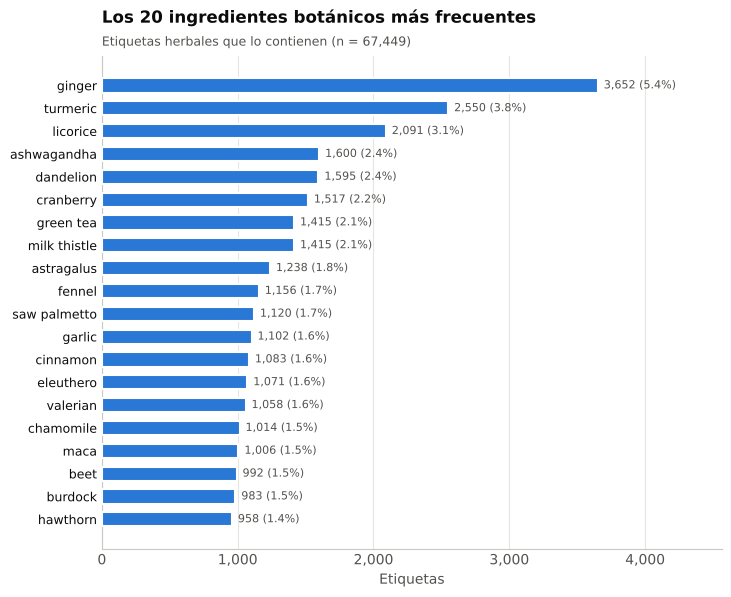

In [8]:
top_ing = (bot.groupby("ingrediente")["dsld_id"].nunique()
              .sort_values(ascending=False).head(20))
tabla_ingredientes = pd.DataFrame({
    "etiquetas": top_ing,
    "pct_del_segmento": (top_ing / N_HERBAL * 100).round(1)})
display(tabla_ingredientes)

fig, ax = plt.subplots(figsize=(8, 6.4))
barras_h(ax, top_ing.index, top_ing.values,
         [f"{v:,} ({v / N_HERBAL:.1%})" for v in top_ing.values])
titular(ax, "Los 20 ingredientes botánicos más frecuentes",
        f"Etiquetas herbales que lo contienen (n = {N_HERBAL:,})")
ax.set_xlabel("Etiquetas")
guardar(fig, "01_ingredientes_top20")

**Hallazgo.** El mercado es muy diverso: el jengibre, el ingrediente más común, aparece en solo 5.4 % de las etiquetas, seguido de cúrcuma (3.8 %) y regaliz (3.1 %). Ningún ingrediente domina el segmento.

## 6. ¿En qué formatos se vende?

Etiquetas herbales por forma de presentación, separadas en activas y descontinuadas. Se muestran las formas con al menos 500 etiquetas.

estatus,descontinuado,en_mercado,total,pct_descontinuado
forma,,,,
Capsule,9974,14575,24549,40.6
Liquid,7830,14949,22779,34.4
Powder,1660,6959,8619,19.3
Tablet or Pill,2803,3085,5888,47.6
Softgel Capsule,1305,1303,2608,50.0
Other (e.g. tea bag),622,947,1569,39.6
Gummy or Jelly,373,776,1149,32.5
Lozenge,95,101,196,48.5
Unknown,40,45,85,47.1


Porcentaje descontinuado en todo el segmento: 36.6%


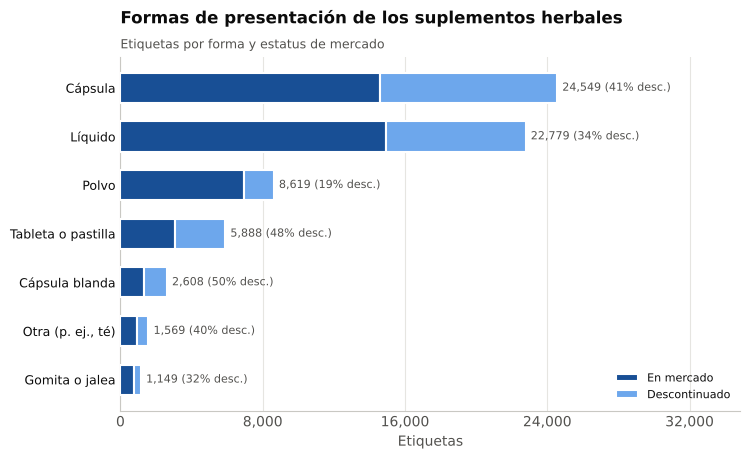

In [9]:
formas = (herbal.groupby(["forma", "estatus"])["dsld_id"].nunique()
                .unstack(fill_value=0)
                .rename(columns={"On Market": "en_mercado", "Off Market": "descontinuado"}))
formas["total"] = formas.sum(axis=1)
formas["pct_descontinuado"] = (formas["descontinuado"] / formas["total"] * 100).round(1)
formas = formas.sort_values("total", ascending=False)
PCT_DESC_GLOBAL = round((herbal["estatus"] == "Off Market").mean() * 100, 1)
display(formas)
print(f"Porcentaje descontinuado en todo el segmento: {PCT_DESC_GLOBAL}%")

g = formas[formas["total"] >= 500]
fig, ax = plt.subplots(figsize=(8, 4.6))
apilado_h(ax, [FORMA_ES[f] for f in g.index], g["en_mercado"].values, g["descontinuado"].values,
          [f"{t:,} ({p:.0f}% desc.)" for t, p in zip(g["total"], g["pct_descontinuado"])])
titular(ax, "Formas de presentación de los suplementos herbales",
        "Etiquetas por forma y estatus de mercado")
ax.set_xlabel("Etiquetas")
guardar(fig, "02_formas")

**Hallazgo.** Cápsulas (24,549) y líquidos (22,779) concentran 70 % del segmento. Los polvos son los que menos se descontinúan (19.3 %), y las cápsulas blandas y las tabletas los que más (50.0 % y 47.6 %), frente a 36.6 % en todo el segmento. Es una diferencia descriptiva: una etiqueta antigua ha tenido más tiempo para salir del mercado, y no hay fecha de salida para comprobarlo.

## 7. ¿Qué ingredientes rotan más?

Entre los ingredientes con al menos 500 etiquetas, los 10 con mayor y los 10 con menor porcentaje de etiquetas descontinuadas.

67 ingredientes con al menos 500 etiquetas


,etiquetas,descontinuadas,pct_descontinuado,grupo
ingrediente,,,,
cardamom,544,325,59.7,Mayor rotación
passionflower,715,390,54.5,Mayor rotación
echinacea angustifolia,752,406,54.0,Mayor rotación
echinacea,763,404,52.9,Mayor rotación
artichoke,593,310,52.3,Mayor rotación
orange,589,307,52.1,Mayor rotación
skullcap,544,279,51.3,Mayor rotación
cinnamon,1083,552,51.0,Mayor rotación
stinging nettle,600,305,50.8,Mayor rotación


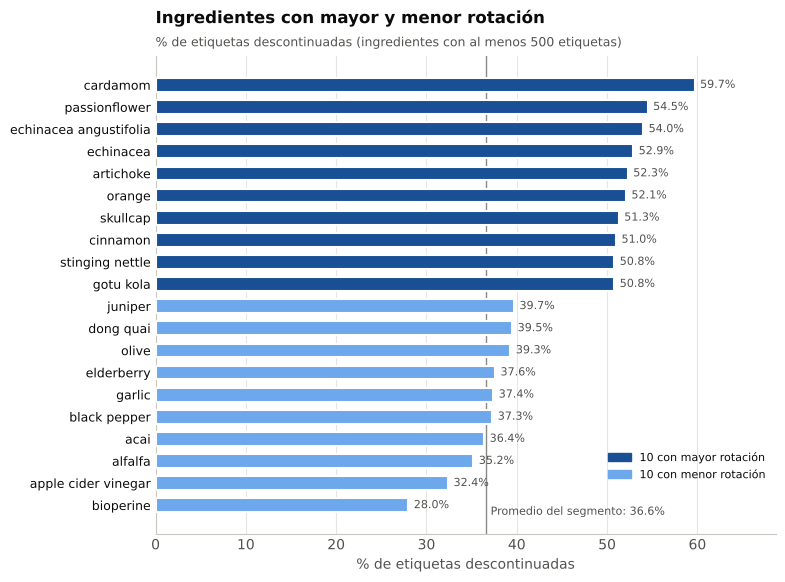

In [10]:
par = (bot[["dsld_id", "ingrediente"]].drop_duplicates()
          .merge(herbal[["dsld_id", "estatus"]], on="dsld_id"))
rot = (par.groupby("ingrediente")["estatus"]
          .agg(etiquetas="size", descontinuadas=lambda s: (s == "Off Market").sum()))
rot["pct_descontinuado"] = (rot["descontinuadas"] / rot["etiquetas"] * 100).round(1)
rot = rot[rot["etiquetas"] >= 500]
print(f"{len(rot)} ingredientes con al menos 500 etiquetas")

altos = rot.sort_values("pct_descontinuado", ascending=False).head(10)
bajos = rot.sort_values("pct_descontinuado", ascending=False).tail(10)
tabla_rotacion = pd.concat([altos.assign(grupo="Mayor rotación"), bajos.assign(grupo="Menor rotación")])
display(tabla_rotacion)

fig, ax = plt.subplots(figsize=(8, 6.2))
nombres = list(altos.index) + list(bajos.index)
vals = list(altos["pct_descontinuado"]) + list(bajos["pct_descontinuado"])
y = np.arange(len(nombres))
colores = [BLUE_DARK] * len(altos) + [BLUE_LIGHT] * len(bajos)
ax.barh(y, vals, height=0.62, color=colores, edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(nombres, fontsize=9, color=INK)
ax.invert_yaxis()
for yi, v in zip(y, vals):
    ax.text(v + 0.6, yi, f"{v:.1f}%", va="center", fontsize=8, color=INK_2)
ax.axvline(PCT_DESC_GLOBAL, color=INK_3, linewidth=1, zorder=2)
ax.text(PCT_DESC_GLOBAL + 0.5, len(nombres) - 0.45, f"Promedio del segmento: {PCT_DESC_GLOBAL}%",
        fontsize=8, color=INK_2, va="bottom")
ax.set_xlim(0, max(vals) * 1.15)
ax.set_xlabel("% de etiquetas descontinuadas")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE_DARK, label="10 con mayor rotación"),
                   plt.Rectangle((0, 0), 1, 1, color=BLUE_LIGHT, label="10 con menor rotación")],
          frameon=False, fontsize=8, loc="lower right", bbox_to_anchor=(1, 0.09))
estilo_ejes(ax, grid="x")
titular(ax, "Ingredientes con mayor y menor rotación",
        "% de etiquetas descontinuadas (ingredientes con al menos 500 etiquetas)")
guardar(fig, "03_rotacion_ingredientes")

**Hallazgo.** El cardamomo (59.7 %), la pasiflora (54.5 %) y la equinácea (52.9 % y 54.0 % para *angustifolia*) son los más descontinuados; bioperine (28.0 %), vinagre de manzana (32.4 %) y alfalfa (35.2 %), los menos. El rango es estrecho (28 % a 60 %) y 63 de los 67 ingredientes quedan por encima del promedio del segmento (36.6 %), que está rebajado por las cargas masivas. Hay que leerlo como rotación relativa, no como causa. *Residuo de limpieza:* «echinacea» y «echinacea angustifolia» aparecen por separado.

## 8. ¿Quién concentra el mercado?

Marcas con más etiquetas herbales. Son **etiquetas**, no productos: una marca puede tener varias versiones del mismo producto (tamaños, sabores, relanzamientos), y marcas casi idénticas aparecen por separado (*TerraVita* y *TerraVita Premium Collection*).

estatus,descontinuado,en_mercado,total,pct_descontinuado
marca,,,,
Hawaii Pharm,1727,2920,4647,37.2
TerraVita Premium Collection,0,3793,3793,0.0
Herb Pharm,2498,724,3222,77.5
Herbal Terra,9,3065,3074,0.3
BulkSupplements.com,670,2017,2687,24.9
TerraVita,0,2419,2419,0.0
Nature's Way,1029,506,1535,67.0
Nature's Answer,988,411,1399,70.6
NOW,853,359,1212,70.4


Marcas distintas: 2,759 | con una sola etiqueta: 1,048 (38%)
Las 10 mayores concentran 36.6% de las etiquetas; las 50 mayores, 59.1%


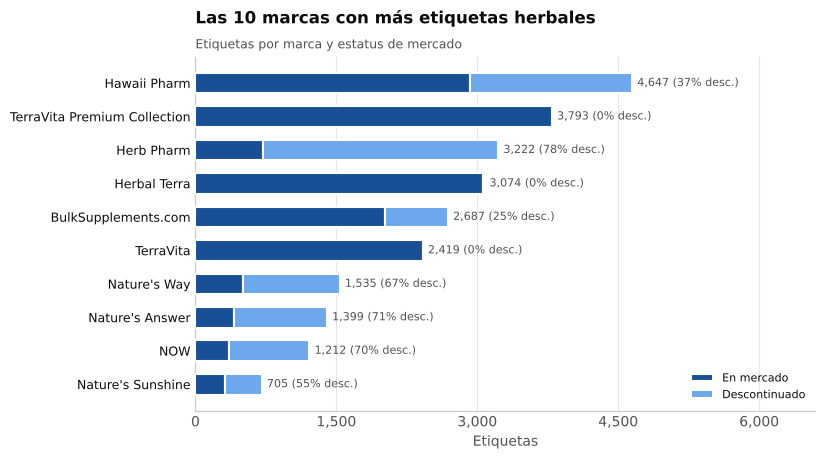

In [11]:
marcas = (herbal.groupby(["marca", "estatus"])["dsld_id"].nunique()
                .unstack(fill_value=0)
                .rename(columns={"On Market": "en_mercado", "Off Market": "descontinuado"}))
marcas["total"] = marcas.sum(axis=1)
marcas["pct_descontinuado"] = (marcas["descontinuado"] / marcas["total"] * 100).round(1)
top_marcas = marcas.sort_values("total", ascending=False).head(10)
display(top_marcas)

N_MARCAS = len(marcas)
una_etiqueta = (marcas["total"] == 1).sum()
print(f"Marcas distintas: {N_MARCAS:,} | con una sola etiqueta: {una_etiqueta:,} ({una_etiqueta / N_MARCAS:.0%})")
print(f"Las 10 mayores concentran {top_marcas['total'].sum() / N_HERBAL:.1%} de las etiquetas; "
      f"las 50 mayores, {marcas['total'].sort_values(ascending=False).head(50).sum() / N_HERBAL:.1%}")

fig, ax = plt.subplots(figsize=(8, 4.6))
apilado_h(ax, top_marcas.index, top_marcas["en_mercado"].values, top_marcas["descontinuado"].values,
          [f"{t:,} ({p:.0f}% desc.)" for t, p in zip(top_marcas["total"], top_marcas["pct_descontinuado"])])
titular(ax, "Las 10 marcas con más etiquetas herbales", "Etiquetas por marca y estatus de mercado")
ax.set_xlabel("Etiquetas")
guardar(fig, "04_marcas")

**Hallazgo.** Hay 2,759 marcas, pero el mercado es de cola larga: 38 % de las marcas tiene una sola etiqueta, y las 10 mayores reúnen 36.6 % de las etiquetas. Las marcas con 0 % de descontinuadas (*TerraVita*, *Herbal Terra*) son las de carga masiva reciente, mientras que marcas tradicionales como *Herb Pharm* (77.5 %), *Nature's Answer* (70.6 %), *NOW* (70.4 %) y *Nature's Way* (67.0 %) tienen más de la mitad de su historial descontinuado.

## 9. ¿Qué combinaciones de ingredientes existen?

El 65 % de las etiquetas herbales contiene un solo botánico. Para las combinaciones se consideran las etiquetas con **2 a 8 botánicos** (las fórmulas más grandes inflarían cualquier par) y se cuentan los pares de ingredientes que aparecen juntos.

Un solo botánico: 65.3% | de 2 a 5: 21.3% | 6 o más: 13.5%


,etiquetas
ginger + turmeric,342
echinacea angustifolia + echinacea purpurea,332
dandelion + milk thistle,322
black pepper + turmeric,269
ginger + licorice,259
passionflower + valerian,218
bioperine + turmeric,213
beet + pomegranate,206
apple cider vinegar + beet,205
marshmallow + slippery elm,203


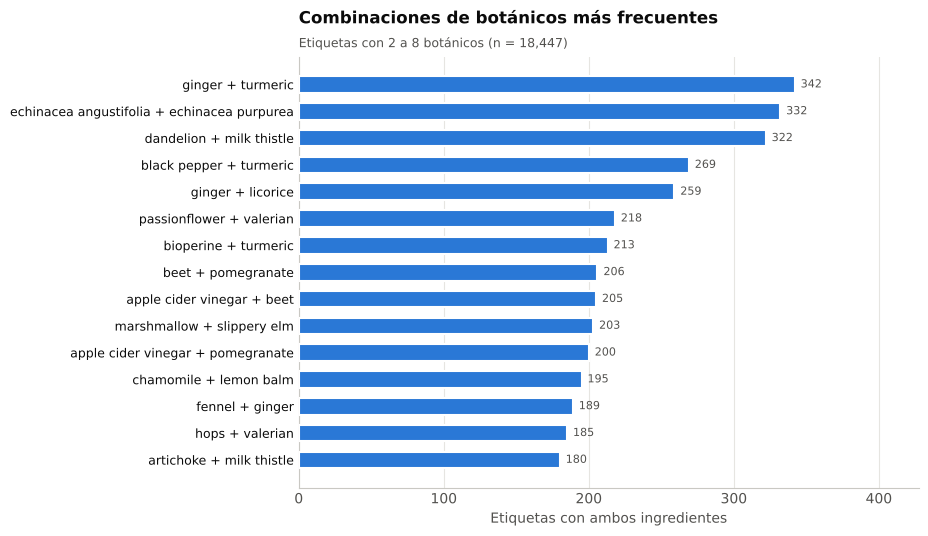

In [12]:
n_bot = bot.groupby("dsld_id")["ingrediente"].nunique()
PCT_UN_BOTANICO = (n_bot == 1).mean() * 100
print(f"Un solo botánico: {PCT_UN_BOTANICO:.1f}% | de 2 a 5: {n_bot.between(2, 5).mean():.1%} "
      f"| 6 o más: {(n_bot >= 6).mean():.1%}")

ids = n_bot[n_bot.between(2, 8)].index
sub = bot[bot["dsld_id"].isin(ids)].drop_duplicates(["dsld_id", "ingrediente"])
cont = collections.Counter()
for _, grupo in sub.groupby("dsld_id")["ingrediente"]:
    for p in itertools.combinations(sorted(grupo), 2):
        cont[p] += 1

pares = pd.Series(cont).sort_values(ascending=False).head(15)
tabla_pares = pares.rename("etiquetas").to_frame()
tabla_pares.index = [f"{a} + {b}" for a, b in pares.index]
display(tabla_pares)

fig, ax = plt.subplots(figsize=(8, 5.6))
barras_h(ax, tabla_pares.index, tabla_pares["etiquetas"].values,
         [f"{v:,}" for v in tabla_pares["etiquetas"]])
titular(ax, "Combinaciones de botánicos más frecuentes",
        f"Etiquetas con 2 a 8 botánicos (n = {len(ids):,})")
ax.set_xlabel("Etiquetas con ambos ingredientes")
guardar(fig, "05_combinaciones")

**Hallazgo.** Las combinaciones más comunes son jengibre + cúrcuma (342 etiquetas), cardo mariano + diente de león (322), pimienta negra + cúrcuma (269), jengibre + regaliz (259) y pasiflora + valeriana (218). Dos pares requieren cuidado: *echinacea angustifolia + purpurea* son dos especies del mismo género y no una combinación real, y los pares con vinagre de manzana, betabel y granada probablemente reflejan una sola familia de gomitas con muchas versiones.

## 10. ¿Qué dosis declaran?

Dosis por porción de los botánicos más comunes en **cápsulas**, en mg. Se usa una dosis por etiqueta e ingrediente (la mediana si se repite). Se excluye *bioperine* (potenciador de absorción, ~5 mg) y *grape* (nombre ambiguo tras la limpieza).

,n,p10,q1,mediana,q3,p90
ingrediente,,,,,,
ginkgo biloba,471.0,40.0,60.0,120.0,120.0,210.0
ginger,644.0,25.0,50.0,120.0,300.0,550.0
dandelion,447.0,20.0,75.0,139.0,240.0,520.0
milk thistle,663.0,100.0,175.0,230.0,300.0,600.0
green tea,581.0,50.0,100.0,250.0,500.0,630.0
ashwagandha,653.0,50.0,150.0,250.0,500.0,1050.0
maca,422.0,100.0,250.0,300.0,500.0,1000.0
saw palmetto,370.0,75.0,100.0,320.0,500.0,763.0
turmeric,1008.0,50.0,200.0,388.0,600.0,825.0


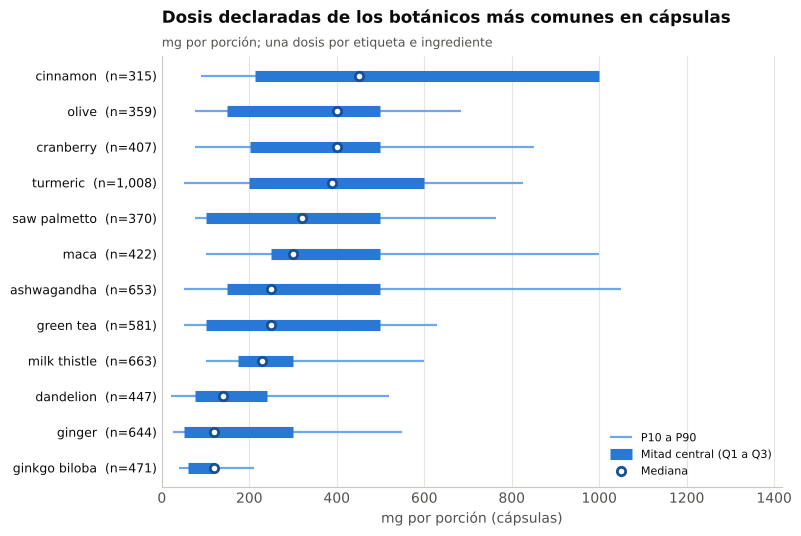

In [13]:
d = bot.merge(herbal[["dsld_id", "forma"]], on="dsld_id")
d = d[d["forma"] == "Capsule"].copy()
d["mg"] = pd.to_numeric(d["cantidad"], errors="coerce")
d = d[(d["unidad"].str.lower() == "mg") & (d["mg"] > 0)]
d = d.groupby(["dsld_id", "ingrediente"], as_index=False)["mg"].median()

n_dosis = d.groupby("ingrediente")["mg"].size()
EXCLUIR = ["bioperine", "grape"]
top_dosis = n_dosis[(n_dosis >= 150) & (~n_dosis.index.isin(EXCLUIR))].sort_values(ascending=False).head(12).index
dosis = (d[d["ingrediente"].isin(top_dosis)].groupby("ingrediente")["mg"]
           .describe(percentiles=[.1, .25, .5, .75, .9])[["count", "10%", "25%", "50%", "75%", "90%"]]
           .round(0).sort_values("50%"))
dosis.columns = ["n", "p10", "q1", "mediana", "q3", "p90"]
display(dosis)


def grafica_dosis(ax, tabla, fs=8):
    y = np.arange(len(tabla))
    ax.hlines(y, tabla["p10"], tabla["p90"], color=BLUE_LIGHT, linewidth=1.6, zorder=2,
              label="P10 a P90")
    ax.hlines(y, tabla["q1"], tabla["q3"], color=BLUE, linewidth=8, zorder=3,
              label="Mitad central (Q1 a Q3)")
    ax.plot(tabla["mediana"], y, "o", markerfacecolor=SURFACE, markeredgecolor=BLUE_DARK,
            markeredgewidth=2, markersize=6, zorder=4, label="Mediana")
    ax.set_yticks(y)
    ax.set_yticklabels([f"{i}  (n={int(n):,})" for i, n in zip(tabla.index, tabla["n"])],
                       fontsize=fs + 1, color=INK)
    ax.set_xlim(0, tabla["p90"].max() * 1.35)
    ax.set_xlabel("mg por porción (cápsulas)")
    ax.legend(frameon=False, fontsize=fs, loc="lower right")
    estilo_ejes(ax, grid="x")


fig, ax = plt.subplots(figsize=(8, 5.6))
grafica_dosis(ax, dosis)
titular(ax, "Dosis declaradas de los botánicos más comunes en cápsulas",
        "mg por porción; una dosis por etiqueta e ingrediente")
guardar(fig, "06_dosis")

**Hallazgo.** El ginkgo es el ingrediente más estandarizado (casi todos declaran 120 mg). La cúrcuma tiene mediana de 388 mg, y la ashwagandha 250 mg, con mucha dispersión (el 10 % más alto declara más de 1,000 mg). Jengibre y diente de león son las dosis más bajas (120 y 139 mg). *Salvedades:* es la dosis declarada en etiqueta (no medida), por **porción** (puede ser más de una cápsula), y el DSLD no distingue entre polvo crudo y extracto estandarizado; «olive» y «cinnamon» pueden mezclar partes distintas de la planta.

## 11. ¿Qué ingredientes van en cada formato?

Porcentaje de las etiquetas de **cada forma** que contienen el ingrediente (así se compara una forma pequeña con una grande). Se muestran los 4 ingredientes más frecuentes de cada forma.

forma,Capsule,Liquid,Powder,Tablet or Pill,Softgel Capsule,Gummy or Jelly
ingrediente,,,,,,
stevia,0.1,1.0,3.0,1.4,0.6,0.0
dandelion,3.2,2.0,1.1,3.0,1.6,0.4
echinacea angustifolia,0.9,1.9,0.2,0.4,3.4,0.0
green tea,3.4,0.7,1.2,2.7,2.7,1.2
ashwagandha,3.6,1.1,1.6,4.1,1.3,3.2
licorice,2.9,3.1,1.2,5.2,5.0,0.2
garlic,2.0,0.7,0.7,4.3,6.5,0.1
turmeric,5.7,1.5,2.6,8.0,2.8,4.9
blueberry,1.0,0.5,2.2,4.2,1.0,9.3


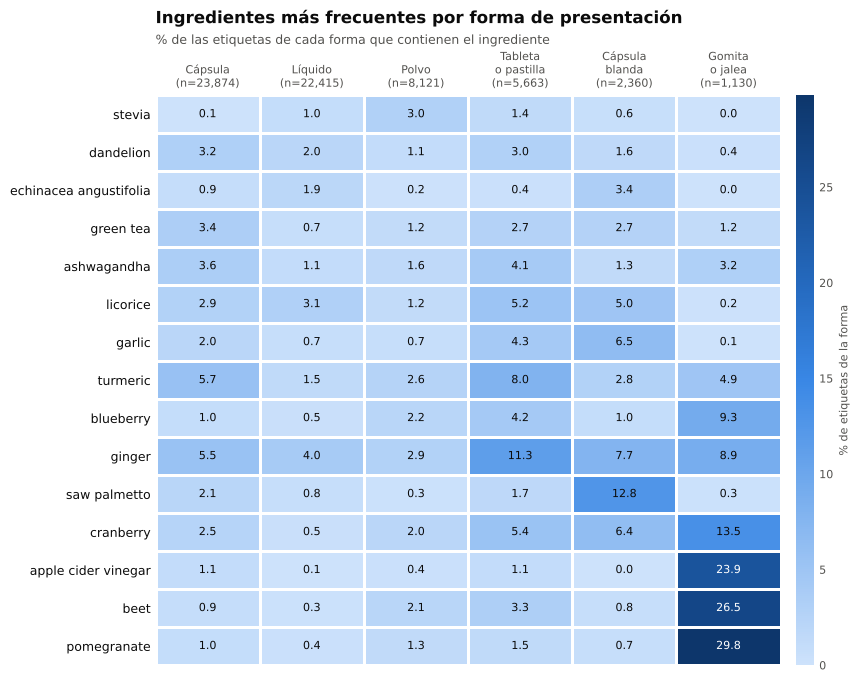

In [14]:
FORMAS = ["Capsule", "Liquid", "Powder", "Tablet or Pill", "Softgel Capsule", "Gummy or Jelly"]
b = (bot[["dsld_id", "ingrediente"]].drop_duplicates()
        .merge(herbal[["dsld_id", "forma"]], on="dsld_id"))
b = b[b["forma"].isin(FORMAS)]

base = b.groupby("forma")["dsld_id"].nunique()
cuenta = b.groupby(["ingrediente", "forma"])["dsld_id"].nunique().unstack(fill_value=0)[FORMAS]
pct = cuenta / base[FORMAS] * 100

sel = []
for f in FORMAS:
    for i in pct[f].sort_values(ascending=False).head(4).index:
        if i not in sel:
            sel.append(i)
mapa = pct.loc[sel]
mapa = mapa.loc[mapa.max(axis=1).sort_values().index].round(1)
display(mapa)


def mapa_calor(ax, mapa, base, fs=8, barra=True):
    vmax = mapa.values.max()
    malla = ax.pcolormesh(mapa.values, cmap=CMAP, vmin=0, vmax=vmax, edgecolors=SURFACE, linewidth=2)
    ax.set_xticks(np.arange(mapa.shape[1]) + 0.5)
    ax.set_xticklabels([f"{FORMA_ES[f].replace(' ', chr(10), 1)}\n(n={base[f]:,})" for f in mapa.columns], fontsize=fs)
    ax.set_yticks(np.arange(mapa.shape[0]) + 0.5)
    ax.set_yticklabels(mapa.index, fontsize=fs + 1, color=INK)
    ax.xaxis.tick_top()
    ax.invert_yaxis()
    for i in range(mapa.shape[0]):
        for j in range(mapa.shape[1]):
            v = mapa.values[i, j]
            ax.text(j + 0.5, i + 0.5, f"{v:.1f}", ha="center", va="center", fontsize=fs,
                    color="white" if v > vmax * 0.55 else INK)
    for lado in ax.spines.values():
        lado.set_visible(False)
    ax.tick_params(length=0)
    if barra:
        cax = make_axes_locatable(ax).append_axes("right", size="3%", pad=0.15)
        cb = plt.colorbar(malla, cax=cax)
        cb.set_label("% de etiquetas de la forma", fontsize=fs, color=INK_2)
        cb.outline.set_visible(False)
        cb.ax.tick_params(length=0, labelsize=fs)


fig, ax = plt.subplots(figsize=(8.5, 7.4))
mapa_calor(ax, mapa, base)
titular(ax, "Ingredientes más frecuentes por forma de presentación",
        "% de las etiquetas de cada forma que contienen el ingrediente", pad=52, y_sub=1.085)
guardar(fig, "07_ingredientes_por_forma")

**Hallazgo.** Las gomitas son un mundo aparte: granada (29.8 %), betabel (26.5 %) y vinagre de manzana (23.9 %) aparecen en cerca de una de cada cuatro, y en cápsulas ronda el 1 %. Las cápsulas blandas se especializan (saw palmetto en 12.8 %), y en tabletas destacan jengibre (11.3 %) y cúrcuma (8.0 %). En cápsulas y líquidos ningún ingrediente pasa de 6 %. Las gomitas son 1,130 etiquetas, probablemente de pocas familias de producto con muchas versiones.

## 12. ¿En qué formas abundan las mezclas?

Una **mezcla** es un ingrediente de categoría *blend* en la etiqueta: mezclas propietarias (*proprietary blend*), pero también complejos con nombre comercial (por ejemplo, *Triphala*). Se calcula el porcentaje de etiquetas de cada forma que tiene al menos una, sin las 4 marcas de carga masiva y solo para formas con 300 o más etiquetas.

,etiquetas,pct_con_mezcla
forma,,
Tableta o pastilla,5888,42.5
"Otra (p. ej., té)",1569,39.9
Líquido,12792,34.7
Cápsula blanda,2608,27.0
Gomita o jalea,1149,24.7
Cápsula,23202,21.5
Polvo,6020,15.5


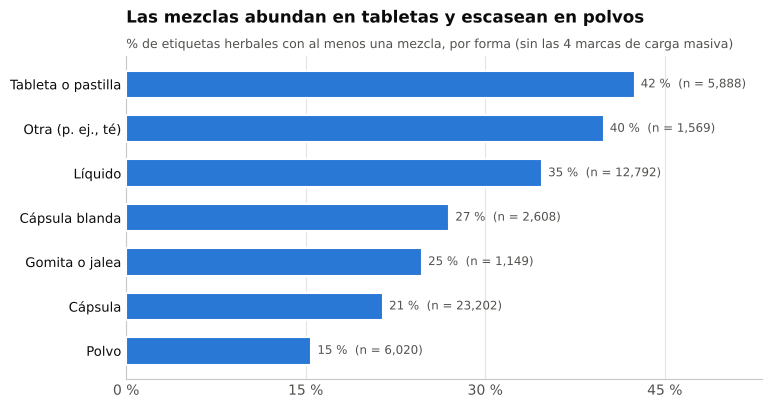

In [15]:
con_mezcla = set(ing.loc[ing["categoria"] == "blend", "dsld_id"])
base_m = herbal[~herbal["carga_masiva"]].copy()
base_m["tiene_mezcla"] = base_m["dsld_id"].isin(con_mezcla)
PCT_MEZCLA = base_m["tiene_mezcla"].mean() * 100

por_forma = (base_m.groupby("forma")
             .agg(etiquetas=("dsld_id", "size"), pct_con_mezcla=("tiene_mezcla", "mean")))
por_forma = por_forma[por_forma["etiquetas"] >= 300].sort_values("pct_con_mezcla", ascending=False)
por_forma["pct_con_mezcla"] = por_forma["pct_con_mezcla"] * 100
por_forma.index = [FORMA_ES.get(i, i) for i in por_forma.index]
por_forma.index.name = "forma"
display(por_forma.round(1))

fig, ax = plt.subplots(figsize=(8.2, 4.2))
barras_h(ax, por_forma.index, por_forma["pct_con_mezcla"].values,
         [f"{p:.0f} %  (n = {n:,})" for p, n in zip(por_forma["pct_con_mezcla"], por_forma["etiquetas"])],
         fs=8.5)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
titular(ax, "Las mezclas abundan en tabletas y escasean en polvos",
        "% de etiquetas herbales con al menos una mezcla, por forma (sin las 4 marcas de carga masiva)")
guardar(fig, "08_mezclas_por_forma")

**Hallazgo.** Sin las 4 marcas de carga masiva, 27 % de las etiquetas herbales tiene al menos una mezcla. Abundan en las tabletas (42 %), en la categoría «otra», que incluye el té (40 %), y en los líquidos (35 %). En cápsulas son 21 %, y en polvos solo 15 %. Dicho de otro modo, un polvo casi siempre es un solo ingrediente, y una tableta o un líquido suele ser una fórmula. *Salvedad:* la categoría *blend* incluye complejos con nombre comercial, no solo mezclas «propietarias».

## 13. ¿Qué palabras usan las marcas en el título?

Además del ingrediente, el título de un producto suele llevar otras palabras: atributos (*organic*, *alcohol free*), beneficios (*support*, *immune*), potencia (*extra strength*), formato (*extract*, *tea*)…

Cómo se calcula (sin las 4 marcas de carga masiva, 53,516 etiquetas):
1. Se separa cada título en palabras, quitando unidades (*mg*, *capsules*…), palabras vacías y las palabras que ya están en el nombre de la marca.
2. Se unen las frases de ingredientes (*milk thistle*, *saw palmetto*, *apple cider vinegar*) para contarlas como un solo término; son frases que aparecen en 50+ títulos y que además están en la lista de ingredientes de esas etiquetas.
3. Cada término se clasifica como **ingrediente** (aparece en la lista de ingredientes de al menos la mitad de las etiquetas donde sale) o como **palabra descriptiva**, con un tema (atributo, beneficio, potencia, formato, parte de la planta, sabor, público, fórmula o nutriente). Los temas vienen de una lista hecha a mano.
4. Se cuenta en cuántas etiquetas aparece cada término (no cuántas veces se repite).

In [16]:
from collections import defaultdict

TEMAS = {
    "Formato o extracto": "extract tea oil tincture syrup juice spray concentrate tonic concentrated freeze dried bags".split(),
    "Parte de la planta": "root leaf seed bark berry fruit flower herb".split(),
    "Atributo": ["organic", "natural", "alcohol free", "sugar free", "gluten free", "vegan", "full spectrum",
                 "standardized", "pure", "whole", "original", "premium", "certified organic", "wild", "non gmo", "kosher"],
    "Potencia": ["strength", "extra strength", "super strength", "maximum strength", "triple strength", "ultra",
                 "max", "maximum", "super", "advanced", "supreme", "power", "gold", "extra", "triple", "potency"],
    "Beneficio": ["support", "immune", "immune support", "cleanse", "detox", "energy", "sleep", "relief", "stress",
                  "defense", "balance", "calm", "boost", "ease", "healthy", "blood pressure", "blood sugar",
                  "adrenal support", "liver", "kidney", "prostate", "thyroid", "brain", "skin", "throat", "heart",
                  "joint", "digestive", "memory", "mood", "weight", "keto"],
    "Sabor": ["flavor", "flavored", "berry flavor", "orange flavor", "raspberry flavor", "cherry flavor",
              "lemon flavor", "vanilla", "chocolate"],
    "Público": ["women", "men", "kids", "children", "adult", "senior"],
    "Fórmula o nutriente": ["formula", "complex", "blend", "compound", "multi", "multivitamin", "vitamin",
                            "one daily", "daily", "zinc", "magnesium", "calcium", "iron", "omega", "protein",
                            "fiber", "phyto", "gen"],
}
TEMA_DE = {palabra: tema for tema, lista in TEMAS.items() for palabra in lista}
FRASES_TEMA = sorted([p for p in TEMA_DE if " " in p], key=lambda p: -len(p.split()))
SIN_VALOR = set("the and with for of plus from by in to a an or your our all as per".split())
UNIDADES = set("mg mcg ml oz fl ct count capsules capsule caps cap tablets tablet tabs tab softgels softgel "
               "gummies gummy liquid powder drops fluid ounce ounces gram grams gm lb lbs pack pk each "
               "bottle serving servings vcaps vcap veggie".split())
NOMBRES_PROPIOS = {"david", "winston", "teapills", "wan"}      # línea de un herbolario y «pastillas» chinas
INGREDIENTES_EXTRA = set("curcumin sambucus triphala cbd orange lemon citrus mint strawberry dgl acv "
                         "mushroom mushrooms greens bitters".split())


def palabras(texto):
    texto = texto.lower().replace("&", " and ")
    return [t for t in re.findall(r"[a-záéíóúñ]+", texto)
            if len(t) >= 3 and t not in SIN_VALOR and t not in UNIDADES]


def unir_frases(lista, frases):
    # Sustituye cada frase conocida por un solo término (la más larga primero).
    salida, i = [], 0
    while i < len(lista):
        for frase in frases:
            n = len(frase.split())
            if " ".join(lista[i:i + n]) == frase:
                salida.append(frase)
                i += n
                break
        else:
            salida.append(lista[i])
            i += 1
    return salida


titulos = herbal.loc[~herbal["carga_masiva"], ["dsld_id", "producto", "marca"]]
N_TITULOS = len(titulos)
palabras_marca = {m: set(palabras(m)) for m in titulos["marca"].unique()}
terminos_por_etiqueta = {
    pid: unir_frases([w for w in palabras(nombre) if w not in palabras_marca[marca] and w not in NOMBRES_PROPIOS],
                     FRASES_TEMA)
    for pid, nombre, marca in zip(titulos["dsld_id"], titulos["producto"], titulos["marca"])}

# Frases de ingrediente: pares de palabras frecuentes que además están en la lista de ingredientes.
texto_ing = (ing.groupby("dsld_id")["ingrediente_original"]
                .apply(lambda s: " | ".join(s).lower().replace("'s", "").replace("’s", "")))
pares = defaultdict(list)
for pid, lista in terminos_por_etiqueta.items():
    for par in set(zip(lista, lista[1:])):
        pares[par].append(pid)

frases_ing = {"apple cider vinegar"}
for par, ids_par in pares.items():
    if len(ids_par) < 50 or (par[0] in TEMA_DE and par[1] in TEMA_DE) or par[1] in {"root", "extract", "oil", "bark", "husk"}:
        continue
    frase = " ".join(par)
    if np.mean([frase in texto_ing.get(p, "") for p in ids_par]) >= 0.5:
        frases_ing.add(frase)
frases_ing = sorted(frases_ing, key=lambda f: -len(f.split()))
terminos_por_etiqueta = {pid: unir_frases(lista, frases_ing) for pid, lista in terminos_por_etiqueta.items()}

# Conteo por término y clasificación
indice = defaultdict(list)
for pid, lista in terminos_por_etiqueta.items():
    for w in set(lista):
        indice[w].append(pid)

filas = []
for w, ids_w in sorted(indice.items(), key=lambda kv: -len(kv[1]))[:400]:
    if w in TEMA_DE:
        tipo = TEMA_DE[w]
    else:
        respaldo = np.mean([w in texto_ing.get(p, "") for p in ids_w])
        tipo = "Ingrediente" if (respaldo >= 0.5 or w in INGREDIENTES_EXTRA) else "Otras palabras"
    filas.append((w, tipo, len(ids_w)))
terminos = pd.DataFrame(filas, columns=["termino", "tipo", "etiquetas"])
terminos["pct"] = (terminos["etiquetas"] / N_TITULOS * 100).round(1)

top50 = terminos.head(50).copy()
top50.index = range(1, 51)
top50.index.name = "posicion"
display(top50)

,termino,tipo,etiquetas,pct
posicion,,,,
1,extract,Formato o extracto,6232,11.6
2,root,Parte de la planta,1825,3.4
3,organic,Atributo,1742,3.3
4,turmeric,Ingrediente,1247,2.3
5,formula,Fórmula o nutriente,989,1.8
6,complex,Fórmula o nutriente,956,1.8
7,echinacea,Ingrediente,906,1.7
8,support,Beneficio,787,1.5
9,oil,Formato o extracto,765,1.4


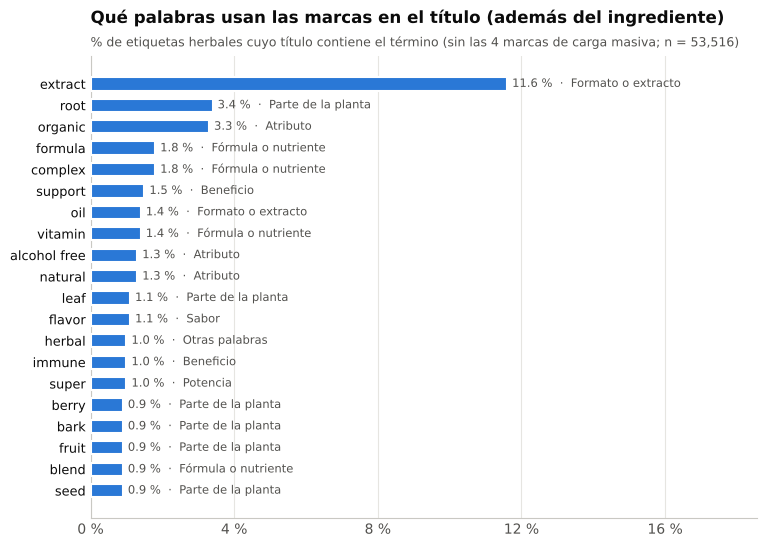

In [17]:
descriptivas = terminos[terminos["tipo"] != "Ingrediente"].head(20)

fig, ax = plt.subplots(figsize=(8.6, 6))
barras_h(ax, descriptivas["termino"], descriptivas["pct"].values,
         [f"{p:.1f} %  ·  {t}" for p, t in zip(descriptivas["pct"], descriptivas["tipo"])], fs=8.3)
ax.set_xlim(0, descriptivas["pct"].max() * 1.6)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
titular(ax, "Qué palabras usan las marcas en el título (además del ingrediente)",
        f"% de etiquetas herbales cuyo título contiene el término (sin las 4 marcas de carga masiva; n = {N_TITULOS:,})")
guardar(fig, "09_palabras_titulo")

**Hallazgo.** «extract» aparece en 11.6 % de los títulos, más de tres veces que «root» (3.4 %) u «organic» (3.3 %). Entre los atributos destacan *organic*, *alcohol free* (1.3 %), *natural* (1.3 %) y *full spectrum* (0.8 %); entre los beneficios, *support* (1.5 %) e *immune* (1.0 %). Los ingredientes más nombrados en los títulos son turmeric (2.3 %), echinacea (1.7 %) y milk thistle (1.4 %).

*Salvedades:* los títulos están en inglés; el tema de cada palabra sale de una lista hecha a mano, y la lista de ingredientes de la gráfica anterior se reutiliza solo como respaldo. Algunos términos son fragmentos (*john wort* es *St. John's wort*; *black* viene de nombres como *black seed*). Para buscar cualquier palabra o ingrediente y ver su dashboard, está el notebook `DSLD_buscador_herbal.ipynb`.

## 14. ¿Qué atributos de etiqueta suben o bajan con el tiempo?

Algunos atributos (*Vegan*, *Sugar Free*, *Gluten Free*, *Organic*…) no vienen en el CSV, sino solo en el JSON de cada etiqueta. Se extrajeron con `dsld_extract_json.py` y se unen por `dsld_id`.

Para que la lectura sea defendible:
- El año es el de **entrada al DSLD** (captura), no el de lanzamiento: se lee como "qué etiquetas se fueron registrando", no como "qué se lanzó".
- Se excluyen las 4 marcas de carga masiva y las marcas con **más de 300 etiquetas**, para que una sola marca no mueva la tendencia.
- Se parte de 2012; 2011 tiene muy pocas etiquetas. Debajo de la gráfica va el número de etiquetas por año.

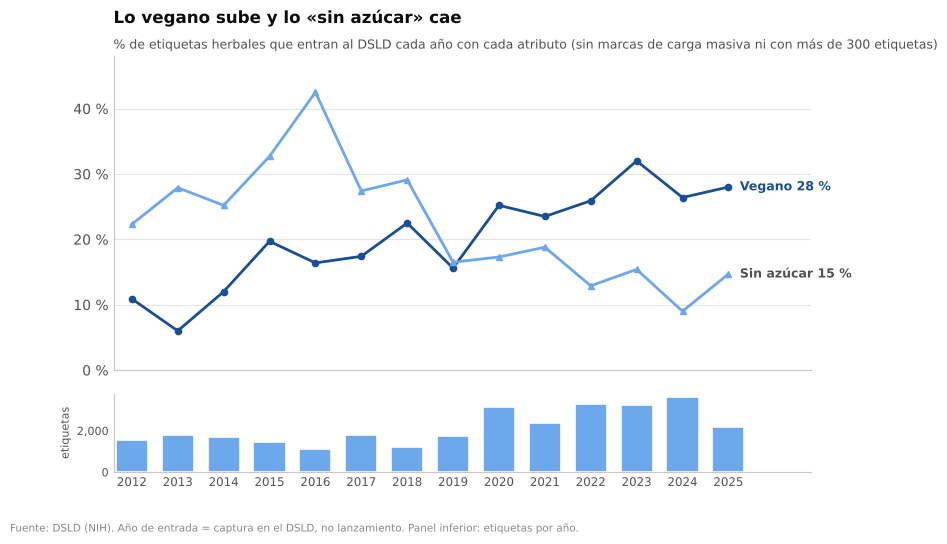

,Vegano,Sin azúcar,etiquetas
anio_entrada,,,
2012,10.9,22.3,1573
2013,6.0,27.9,1784
2014,12.0,25.2,1711
2015,19.7,32.7,1463
2016,16.4,42.5,1120
2017,17.4,27.4,1801
2018,22.5,29.1,1194
2019,15.6,16.5,1747
2020,25.2,17.3,3152


In [18]:
if not os.path.exists(EXTRA_PATH):
    print(f"No se encontró {EXTRA_PATH}. Genera el archivo con dsld_extract_json.py para ver esta sección.")
else:
    extra = pd.read_csv(EXTRA_PATH, dtype=str, keep_default_na=False)[["dsld_id", "target_groups"]]
    base = herbal.loc[~herbal["carga_masiva"]].merge(extra, on="dsld_id", how="left")
    marcas_grandes = base["marca"].value_counts()
    marcas_grandes = marcas_grandes[marcas_grandes > 300].index
    base = base[~base["marca"].isin(marcas_grandes) & (base["anio_entrada"] >= 2012)]

    ATRIBUTOS = {"Vegan": "Vegano", "Sugar Free": "Sin azúcar"}
    por_anio = pd.DataFrame({
        es: base.groupby("anio_entrada")["target_groups"]
                .apply(lambda s: s.str.contains(k, regex=False).mean() * 100)
        for k, es in ATRIBUTOS.items()}).round(1)
    n_anio = base["anio_entrada"].value_counts().sort_index()

    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 5.4), sharex=True,
                                  gridspec_kw={"height_ratios": [4, 1], "hspace": 0.12})
    estilo = {"Vegano": (BLUE_DARK, "o"), "Sin azúcar": (BLUE_LIGHT, "^")}
    for nombre, (color, marcador) in estilo.items():
        ax.plot(por_anio.index, por_anio[nombre], color=color, linewidth=2,
                marker=marcador, markersize=4.5, zorder=3)
        ax.text(por_anio.index[-1] + 0.25, por_anio[nombre].iloc[-1],
                f"{nombre} {por_anio[nombre].iloc[-1]:.0f} %",
                color=color if nombre == "Vegano" else INK_2, fontsize=9,
                fontweight="bold", va="center")
    ax.set_ylim(0, 48)
    ax.set_xlim(2011.6, 2026.8)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f} %"))
    estilo_ejes(ax, grid="y")
    ax2.bar(n_anio.index, n_anio.values, width=0.7, color=BLUE_LIGHT, edgecolor=SURFACE, linewidth=1.2)
    estilo_ejes(ax2)
    ax2.yaxis.set_major_formatter(miles)
    ax2.set_xticks(n_anio.index)
    ax2.set_xticklabels([str(a) for a in n_anio.index], fontsize=8.5)
    ax2.set_ylabel("etiquetas", fontsize=8)
    ax2.tick_params(axis="y", labelsize=8)
    titular(ax, "Lo vegano sube y lo «sin azúcar» cae",
            "% de etiquetas herbales que entran al DSLD cada año con cada atributo (sin marcas de carga masiva ni con más de 300 etiquetas)")
    fig.text(0.01, 0.0, "Fuente: DSLD (NIH). Año de entrada = captura en el DSLD, no lanzamiento. Panel inferior: etiquetas por año.",
             fontsize=7.5, color=INK_3)
    guardar(fig, "10_atributos_por_anio")

    tabla_atributos = por_anio.assign(etiquetas=n_anio)
    tabla_atributos.index.name = "anio_entrada"
    display(tabla_atributos)

**Hallazgo.** Entre las etiquetas que se registraron cada año, lo **vegano** pasa de 11 % (2012) a 28 % (2025), con un máximo de 32 % en 2023. Lo **«sin azúcar»** hace lo contrario: llega a 43 % en 2016 y cae a 9-15 % en 2024-2025. Son los cambios más claros; el resto de los atributos revisados (sin gluten, sin lácteos) sube y baja sin una dirección definida. Como el año es el de captura, esto describe qué etiquetas se registraron, no cuándo se lanzaron.

## 15. Conclusiones y limitaciones

**Qué dicen los datos**
- El segmento herbal es grande (67,449 etiquetas) y muy fragmentado: ningún ingrediente supera el 6 % de las etiquetas y 38 % de las marcas tiene una sola.
- La mayoría de los productos son de **un solo botánico** (65 %); las combinaciones frecuentes son pocas y bastante clásicas (jengibre + cúrcuma, cúrcuma + pimienta negra, pasiflora + valeriana).
- Cada formato tiene su propio perfil de ingredientes. Las **gomitas** se concentran en pocos ingredientes de fruta; **cápsulas y líquidos** son los formatos más saturados y diversos.
- Las dosis declaradas se agrupan en valores redondos (250, 300, 500 mg), con excepciones muy estandarizadas como el ginkgo (120 mg).
- Las **mezclas** (27 % de las etiquetas) se concentran en tabletas (42 %) y líquidos (35 %) y casi no aparecen en polvos (15 %).
- En los títulos, la palabra más repetida (aparte del ingrediente) es *extract*, con 11.6 % de las etiquetas; le siguen *root* y *organic* (3.4 % y 3.3 %).
- Entre las etiquetas que se van registrando, lo **vegano** crece (11 % en 2012, 28 % en 2025) y lo **«sin azúcar»** cae (43 % en 2016, 9-15 % en 2024-2025).

**Para pensar un producto nuevo (lectura, no recomendación):** el dato describe qué hay en el mercado, no qué se vende ni qué funciona. Sirve para ubicar ingredientes y dosis de referencia y para ver dónde hay pocas etiquetas; la demanda, las ventas y la regulación aplicable (por ejemplo, COFEPRIS en México) hay que estudiarlas con otras fuentes.

**Limitaciones**
- Los datos vienen de lo **declarado en etiquetas**; el NIH no verifica su exactitud.
- **No hay fecha de lanzamiento** y la fecha de entrada refleja cuándo se capturó la etiqueta en el DSLD, no cuándo salió al mercado. Por eso la única tendencia que se muestra (sección 14) es de atributos de las etiquetas registradas, con marcas de carga masiva y marcas grandes excluidas.
- Las **cargas masivas** de unas pocas marcas inflan el número de etiquetas y bajan el porcentaje global de descontinuadas (36.6 % con todas, 42.9 % sin ellas).
- Los conteos son de **etiquetas**, no de productos distintos.
- La limpieza de nombres es aproximada (por ejemplo, *echinacea* y *echinacea angustifolia* quedan separadas).
- Los atributos de etiqueta (vegano, sin azúcar…) vienen del JSON y los declara el fabricante; la mayoría de los *claims* son del tipo genérico «estructura/función» y no se analizan.
- Datos de EE. UU.: no equivalen al mercado mexicano.

## 16. Exportar tablas

Guarda en Drive las tablas de cada análisis y los datos limpios del segmento, por si se quieren usar en Tableau o Power BI.

In [19]:
tablas = {
    "ingredientes_top20": tabla_ingredientes, "formas": formas, "rotacion_ingredientes": tabla_rotacion,
    "marcas_top10": top_marcas, "combinaciones": tabla_pares, "dosis_capsulas": dosis,
    "ingredientes_por_forma": mapa, "mezclas_por_forma": por_forma,
    "palabras_titulo_top50": top50,
}
for nombre, t in tablas.items():
    t.to_csv(os.path.join(TAB_DIR, f"{nombre}.csv"), encoding="utf-8-sig")

herbal[["dsld_id", "producto", "marca", "tipo", "forma", "estatus", "anio_entrada"]].to_csv(
    os.path.join(TAB_DIR, "herbal_productos.csv"), index=False, encoding="utf-8-sig")
bot[["dsld_id", "ingrediente_original", "ingrediente", "cantidad", "unidad"]].to_csv(
    os.path.join(TAB_DIR, "herbal_ingredientes_botanicos.csv"), index=False, encoding="utf-8-sig")
print("Guardado en", TAB_DIR)

## 17. Dashboard resumen

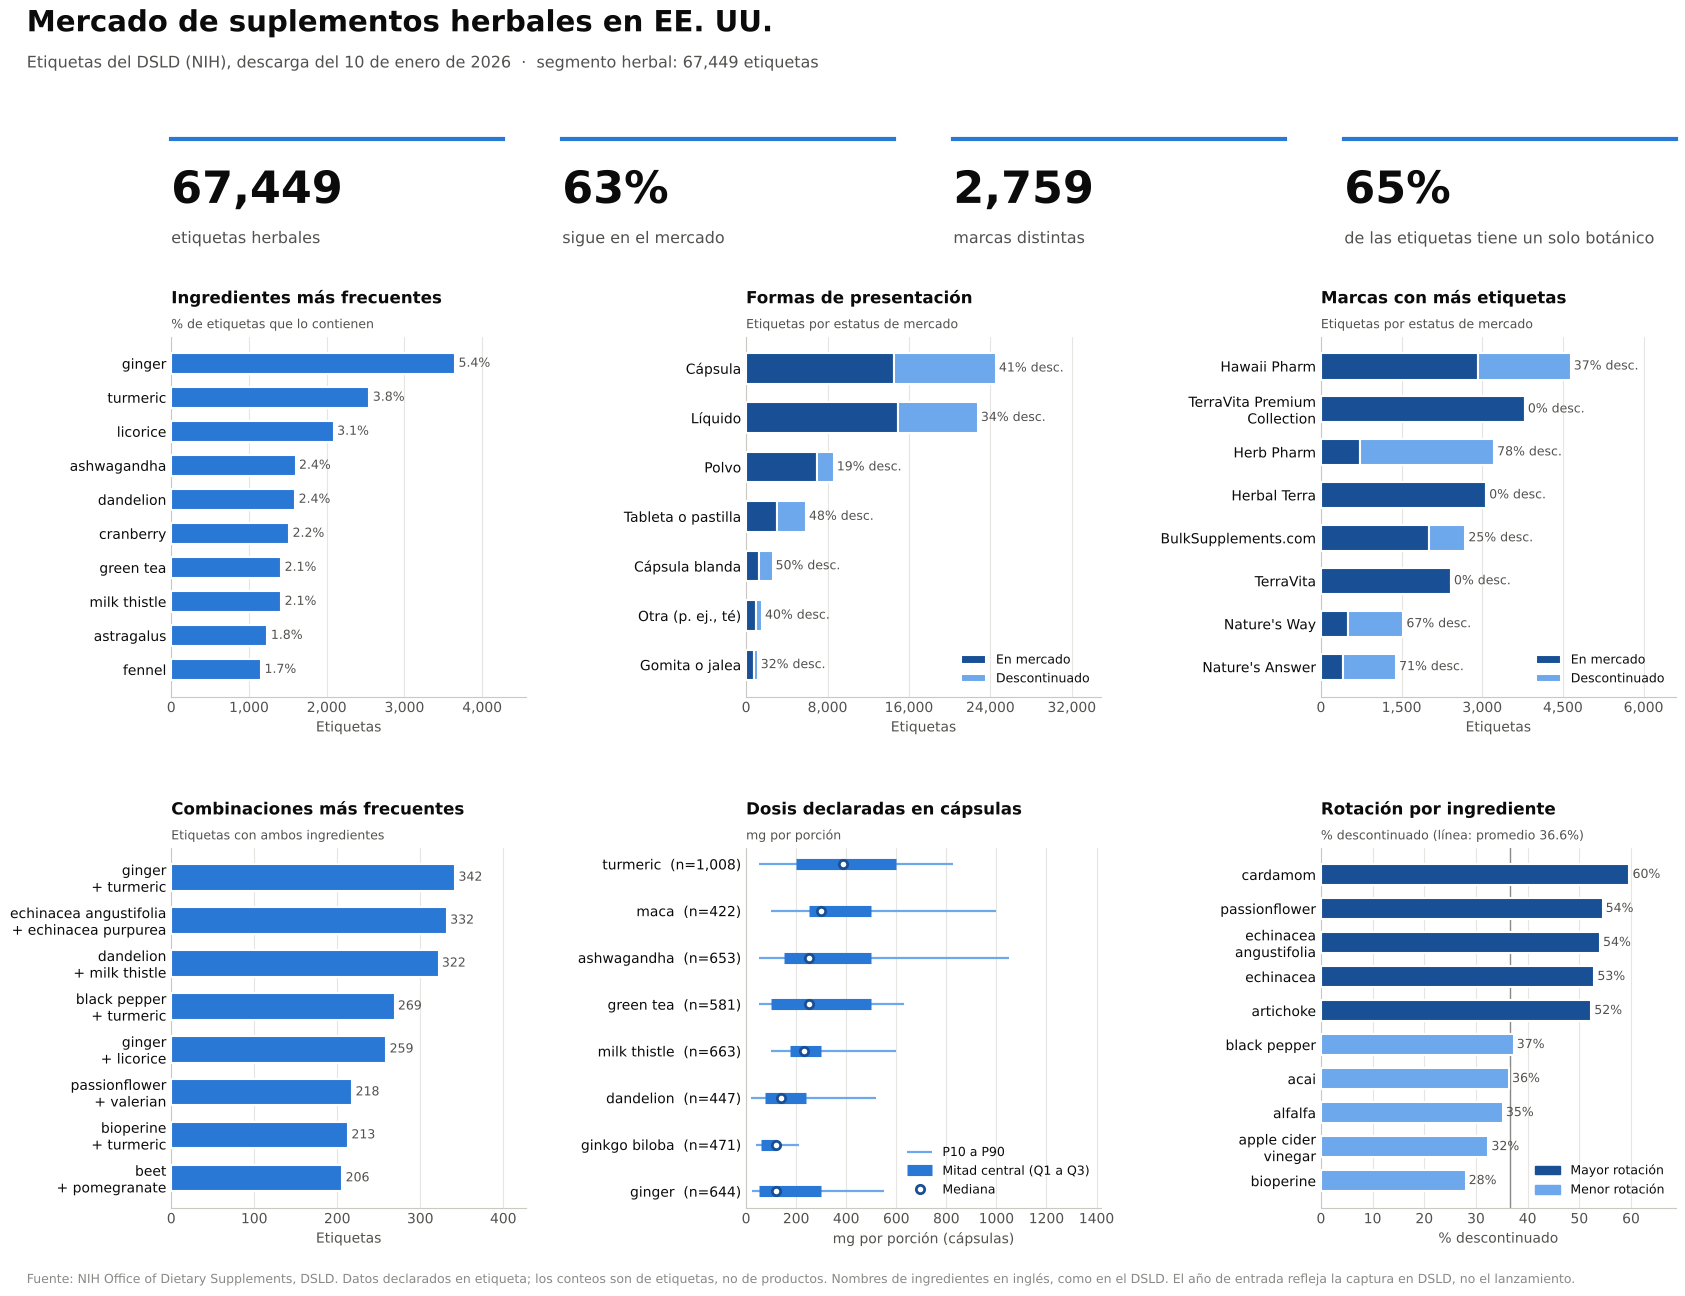

In [20]:
fig = plt.figure(figsize=(17, 13.2))
gs_kpi = fig.add_gridspec(1, 4, left=0.10, right=0.985, top=0.885, bottom=0.805, wspace=0.18)
gs = fig.add_gridspec(2, 3, left=0.10, right=0.985, top=0.735, bottom=0.075, wspace=0.62, hspace=0.42)

fig.text(0.015, 0.972, "Mercado de suplementos herbales en EE. UU.", fontsize=21,
         fontweight="bold", color=INK, va="center")
fig.text(0.015, 0.942, f"Etiquetas del DSLD (NIH), descarga del 10 de enero de 2026  ·  "
         f"segmento herbal: {N_HERBAL:,} etiquetas", fontsize=11.5, color=INK_2, va="center")

# --- Indicadores -----------------------------------------------------------------
pct_en_mercado = (herbal["estatus"] == "On Market").mean() * 100
indicadores = [
    (f"{N_HERBAL:,}", "etiquetas herbales"),
    (f"{pct_en_mercado:.0f}%", "sigue en el mercado"),
    (f"{N_MARCAS:,}", "marcas distintas"),
    (f"{PCT_UN_BOTANICO:.0f}%", "de las etiquetas tiene un solo botánico"),
]
for k, (valor, texto) in enumerate(indicadores):
    ax = fig.add_subplot(gs_kpi[0, k])
    ax.axis("off")
    ax.plot([0, 1], [1, 1], color=BLUE, linewidth=3, transform=ax.transAxes, clip_on=False)
    ax.text(0, 0.50, valor, fontsize=32, fontweight="bold", color=INK, va="center", transform=ax.transAxes)
    ax.text(0, 0.05, texto, fontsize=11.5, color=INK_2, va="center", transform=ax.transAxes)

# --- 1. Ingredientes -----------------------------------------------------------------
ax = fig.add_subplot(gs[0, 0])
t = top_ing.head(10)
barras_h(ax, t.index, t.values, [f"{v / N_HERBAL:.1%}" for v in t.values], fs=9)
titular(ax, "Ingredientes más frecuentes", "% de etiquetas que lo contienen", size=12)
ax.set_xlabel("Etiquetas")

# --- 2. Formas -----------------------------------------------------------------------
ax = fig.add_subplot(gs[0, 1])
g = formas[formas["total"] >= 1000]
apilado_h(ax, [FORMA_ES[f] for f in g.index], g["en_mercado"].values, g["descontinuado"].values,
          [f"{p:.0f}% desc." for p in g["pct_descontinuado"]], fs=9)
titular(ax, "Formas de presentación", "Etiquetas por estatus de mercado", size=12)
ax.set_xlabel("Etiquetas")

# --- 3. Marcas -----------------------------------------------------------------------
ax = fig.add_subplot(gs[0, 2])
g = top_marcas.head(8)
apilado_h(ax, [envolver(m) for m in g.index],
          g["en_mercado"].values, g["descontinuado"].values,
          [f"{p:.0f}% desc." for p in g["pct_descontinuado"]], fs=9)
titular(ax, "Marcas con más etiquetas", "Etiquetas por estatus de mercado", size=12)
ax.set_xlabel("Etiquetas")

# --- 4. Combinaciones ----------------------------------------------------------------
ax = fig.add_subplot(gs[1, 0])
t = tabla_pares.head(8)
barras_h(ax, [envolver(p) for p in t.index], t["etiquetas"].values,
         [f"{v:,}" for v in t["etiquetas"]], fs=9)
titular(ax, "Combinaciones más frecuentes", "Etiquetas con ambos ingredientes", size=12)
ax.set_xlabel("Etiquetas")

# --- 5. Dosis ------------------------------------------------------------------------
ax = fig.add_subplot(gs[1, 1])
t = dosis.sort_values("n", ascending=False).head(8).sort_values("mediana")
grafica_dosis(ax, t, fs=9)
titular(ax, "Dosis declaradas en cápsulas", "mg por porción", size=12)

# --- 6. Rotación ---------------------------------------------------------------------
ax = fig.add_subplot(gs[1, 2])
a, b_ = altos.head(5), bajos.tail(5)
nombres = [envolver(n) for n in list(a.index) + list(b_.index)]
vals = list(a["pct_descontinuado"]) + list(b_["pct_descontinuado"])
y = np.arange(len(nombres))
ax.barh(y, vals, height=0.62, color=[BLUE_DARK] * 5 + [BLUE_LIGHT] * 5, edgecolor=SURFACE,
        linewidth=1.5, zorder=3)
ax.set_yticks(y)
ax.set_yticklabels(nombres, fontsize=10, color=INK)
ax.invert_yaxis()
for yi, v in zip(y, vals):
    ax.text(v + 0.6, yi, f"{v:.0f}%", va="center", fontsize=9, color=INK_2)
ax.axvline(PCT_DESC_GLOBAL, color=INK_3, linewidth=1, zorder=2)
ax.set_xlim(0, max(vals) * 1.15)
ax.set_xlabel("% descontinuado")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE_DARK, label="Mayor rotación"),
                   plt.Rectangle((0, 0), 1, 1, color=BLUE_LIGHT, label="Menor rotación")],
          frameon=False, fontsize=9, loc="lower right")
estilo_ejes(ax, grid="x")
titular(ax, "Rotación por ingrediente", f"% descontinuado (línea: promedio {PCT_DESC_GLOBAL}%)", size=12)

fig.text(0.015, 0.018, "Fuente: NIH Office of Dietary Supplements, DSLD. Datos declarados en etiqueta; "
         "los conteos son de etiquetas, no de productos. Nombres de ingredientes en inglés, como en el DSLD. "
         "El año de entrada refleja la captura en DSLD, no el lanzamiento.",
         fontsize=9, color=INK_3)
guardar(fig, "00_dashboard")